# Heart-Disease Risk Bayesian Network
### Parameter Learning from Patient Data + Approximate Inference by Sampling — organised with the Interpretable Context Methodology (ICM)

| | |
|---|---|
| **Student** | Rushikesh Ukhade (MIS 612302064) |
| **Institute** | COEP Technological University, Pune — B.Tech (Robotics & AI), T.Y. |
| **Course / Evaluation** | Advanced Artificial Intelligence (MRAIPEC702-A) — TA-2 |
| **Syllabus topics** | Unit 3 — Approximate Inference (sampling); Unit 4 — Learning in Bayesian networks |
| **Tools** | Python 3, NumPy, pandas, Matplotlib, NetworkX, pgmpy (only for cross-checking) |

## 1. Why this project?
In **TA-1** we analysed the paper *"Interpretable Context Methodology: Folder Structure as Agentic Architecture"* (arXiv 2603.16021).
ICM structures a workflow as **folders of stages**: **one stage, one job**, hand-offs through **plain-text files**, and **layered context loading** (a stage sees only the files it needs).

In **TA-2** we apply ICM to a medical risk-modelling task. We build a Bayesian network for **heart-disease risk**, then

1. **learn its probabilities from patient records** (maximum likelihood vs Bayesian/Laplace estimation), and
2. answer diagnostic questions with **approximate inference** — *rejection sampling*, *likelihood weighting* and *Gibbs sampling* — checked against exact inference.

| ICM principle | How it is used here |
|---|---|
| One stage, one job | `01_structure` → `02_data` → `03_learning` → `04_exact` → `05_crosscheck` → `06_approx` → `07_evaluation` → `08_report` |
| Plain text as the interface | network, data (`patients.csv`), learned CPTs, queries, results and report are `.json` / `.csv` / `.md` files |
| Layered context loading | `run_stage()` gives a stage only its declared inputs. The **answer key** (true parameters) is visible **only** to the evaluation stage — learning never sees it |

> ⚠️ The patient cohort is **synthetic** (sampled from a hidden, textbook-style parameter set) so that we know the ground truth and can measure how well learning and sampling work. This is an educational model, **not clinical advice**. A real discretised dataset (e.g. UCI Heart Disease) can replace `patients.csv` if it uses the same columns.

## 2. Setup and the ICM stage runner

In [1]:
import io, json, re, shutil, time, warnings
from itertools import product
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

warnings.filterwarnings("ignore")
WS = Path("icm_workspace_heart")
if WS.exists():
    shutil.rmtree(WS)
WS.mkdir()

def write_text(rel, text):
    p = WS / rel
    p.parent.mkdir(parents=True, exist_ok=True)
    p.write_text(text, encoding="utf-8")
    return p

def run_stage(name, inputs, fn, output):
    """ICM stage runner: ONE stage, ONE job. Loads ONLY the declared inputs, writes ONE output file."""
    loaded = {rel: (WS / rel).read_text(encoding="utf-8") for rel in inputs}
    out = fn(loaded)
    write_text(output, out)
    print(f"[{name:<14}] inputs={len(inputs)} ({sum(map(len, loaded.values()))} chars) -> {output} ({len(out)} chars)")
    return out

## 3. Stage 00 — Context
Reference material for the whole pipeline: what is modelled, the allowed states of each variable and the rules every stage must respect.

In [2]:
CONTEXT = """# Context: heart-disease risk Bayesian network

PURPOSE: Educational model of heart-disease risk. NOT FOR CLINICAL USE.
DATA: synthetic patient cohort (one row per patient, one column per variable).

VARIABLES:
age: young, middle, old
smoking: no, yes
exercise: regular, low
obesity: no, yes
bp: normal, high
chol: normal, high
heart: no, yes
chestpain: no, yes
ecg: normal, abnormal

RULES:
- The graph must be a DAG.
- Learning stages may use patients.csv but NEVER the answer key.
- Every CPT row must sum to 1.
- Approximate inference is judged against exact inference.
"""
write_text("00_context/CONTEXT.md", CONTEXT)
print(CONTEXT)

# Context: heart-disease risk Bayesian network

PURPOSE: Educational model of heart-disease risk. NOT FOR CLINICAL USE.
DATA: synthetic patient cohort (one row per patient, one column per variable).

VARIABLES:
age: young, middle, old
smoking: no, yes
exercise: regular, low
obesity: no, yes
bp: normal, high
chol: normal, high
heart: no, yes
chestpain: no, yes
ecg: normal, abnormal

RULES:
- The graph must be a DAG.
- Learning stages may use patients.csv but NEVER the answer key.
- Every CPT row must sum to 1.
- Approximate inference is judged against exact inference.



## 4. Stage 01 — Network structure
**Job:** read the variables from the context, add the causal structure and write `network.json`.

Medical story: **age** influences smoking, exercise habits, blood pressure and cholesterol; **low exercise → obesity**; obesity raises BP and cholesterol;
**BP + cholesterol + smoking → heart disease**; heart disease produces the observable **chest pain** and **abnormal ECG**.

[01_structure  ] inputs=1 (574 chars) -> 01_structure/network.json (1338 chars)


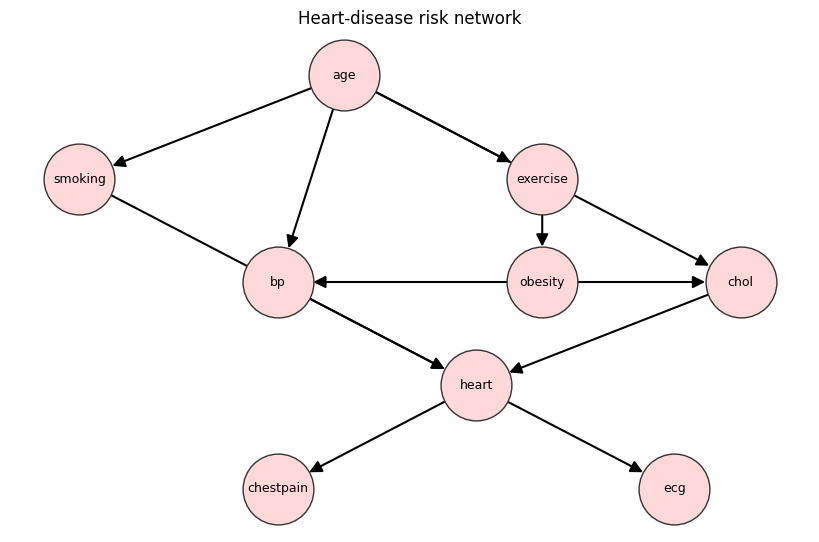

Topological order: ['age', 'smoking', 'exercise', 'obesity', 'bp', 'chol', 'heart', 'chestpain', 'ecg']
Parameters to learn: 34 free probabilities


In [3]:
PARENTS = {
    "age": [], "smoking": ["age"], "exercise": ["age"], "obesity": ["exercise"],
    "bp": ["age", "obesity"], "chol": ["age", "obesity"],
    "heart": ["bp", "chol", "smoking"], "chestpain": ["heart"], "ecg": ["heart"],
}

def stage_structure(loaded):
    block = loaded["00_context/CONTEXT.md"].split("VARIABLES:")[1].split("\n\n")[0]
    states = {l.split(":")[0].strip(): [s.strip() for s in l.split(":")[1].split(",")]
              for l in block.strip().splitlines()}
    g = nx.DiGraph([(p, c) for c, ps in PARENTS.items() for p in ps]); g.add_nodes_from(states)
    assert nx.is_directed_acyclic_graph(g) and set(states) == set(PARENTS)
    net = {"topological_order": list(nx.topological_sort(g)),
           "nodes": {v: {"states": states[v], "parents": PARENTS[v]} for v in states}}
    return json.dumps(net, indent=2)

_ = run_stage("01_structure", ["00_context/CONTEXT.md"], stage_structure, "01_structure/network.json")

# --- helpers shared by all later stages (a tiny Bayesian-network toolkit) ---
def load_net(text):
    net = json.loads(text)
    S = {v: d["states"] for v, d in net["nodes"].items()}          # states
    P = {v: d["parents"] for v, d in net["nodes"].items()}         # parents
    C = {v: [c for c in P if v in P[c]] for v in P}                # children
    return net, S, P, C, net["topological_order"]

net, S, P, C, ORDER = load_net((WS / "01_structure/network.json").read_text())
G = nx.DiGraph([(p, c) for c, ps in P.items() for p in ps])
pos = {"age": (2, 4), "smoking": (0, 3), "exercise": (3.5, 3), "obesity": (3.5, 2), "bp": (1.5, 2), "chol": (5, 2),
       "heart": (3, 1), "chestpain": (1.5, 0), "ecg": (4.5, 0)}
plt.figure(figsize=(8, 5)); nx.draw(G, pos, with_labels=True, node_size=2600, node_color="#ffd9d9",
                                    edgecolors="#333", font_size=9, arrowsize=18, width=1.5)
plt.title("Heart-disease risk network"); plt.show()
print("Topological order:", ORDER)
print("Parameters to learn:", sum(np.prod([len(S[p]) for p in P[v]] or [1]) * (len(S[v]) - 1) for v in S), "free probabilities")

## 5. Toolkit: CPT storage, sampling and exact inference
* A CPT is stored as `CPT[var][(parent state indices)] -> probability vector`.
* `forward_sample` draws a full patient by **ancestral sampling** (parents before children).
* `exact_posterior` computes the exact answer by **enumeration** over the joint (768 configurations — small enough) and is our *reference* for judging approximate methods.

In [4]:
def cpt_from_json(S, P, js):
    return {v: {(tuple(S[p].index(s) for p, s in zip(P[v], key.split("|"))) if P[v] else ()): np.array(row, dtype=float)
                for key, row in rows.items()} for v, rows in js.items()}

def cpt_to_json(S, P, CPT):
    return {v: {"|".join(S[p][i] for p, i in zip(P[v], idx)): [float(x) for x in row] for idx, row in rows.items()}
            for v, rows in CPT.items()}

def draw(rng, probs):
    return min(int(np.searchsorted(np.cumsum(probs), rng.random(), side="right")), len(probs) - 1)

def forward_sample(rng, P, CPT, order):
    x = {}
    for v in order:
        x[v] = draw(rng, CPT[v][tuple(x[p] for p in P[v])])
    return x

def joint_prob(x, P, CPT):
    pr = 1.0
    for v in x:
        pr *= CPT[v][tuple(x[p] for p in P[v])][x[v]]
    return pr

def exact_posterior(S, P, CPT, order, query, evidence):
    """Exact P(query | evidence) by summing the joint over all hidden variables (enumeration)."""
    free = [v for v in order if v not in evidence]
    post = np.zeros(len(S[query]))
    for combo in product(*[range(len(S[v])) for v in free]):
        x = dict(evidence); x.update(zip(free, combo))
        post[x[query]] += joint_prob(x, P, CPT)
    z = post.sum()
    return (post / z if z > 0 else np.full(len(S[query]), np.nan)), z

def ev_idx(S, evidence):                    # {"bp": "high"} -> {"bp": 1}
    return {v: S[v].index(s) for v, s in evidence.items()}

## 6. Stage 02 — Patient data
**Job:** produce `patients.csv` (5,000 patients). The data come from a hidden **answer key** (the "real world"). The key is saved in `99_answer_key/` and is read **only** by the evaluation stage (stage 07).

In [5]:
def _b(p): return [round(1 - p, 6), p]       # binary row [P(first state), P(second state)]

TRUTH = {   # hidden "real-world" probabilities (answer key)
    "age":       {"": [0.30, 0.40, 0.30]},
    "smoking":   {"young": _b(.30), "middle": _b(.28), "old": _b(.20)},                    # P(smoking=yes | age)
    "exercise":  {"young": _b(.30), "middle": _b(.45), "old": _b(.60)},                    # P(exercise=low | age)
    "obesity":   {"regular": _b(.20), "low": _b(.45)},                                     # P(obesity=yes | exercise)
    "bp":        {"young|no": _b(.10), "young|yes": _b(.25), "middle|no": _b(.25),
                  "middle|yes": _b(.45), "old|no": _b(.40), "old|yes": _b(.65)},           # P(bp=high | age, obesity)
    "chol":      {"young|no": _b(.15), "young|yes": _b(.35), "middle|no": _b(.25),
                  "middle|yes": _b(.50), "old|no": _b(.35), "old|yes": _b(.60)},           # P(chol=high | age, obesity)
    "heart":     {"normal|normal|no": _b(.03), "normal|normal|yes": _b(.10),
                  "normal|high|no": _b(.10),   "normal|high|yes": _b(.22),
                  "high|normal|no": _b(.12),   "high|normal|yes": _b(.28),
                  "high|high|no": _b(.25),     "high|high|yes": _b(.50)},                  # P(heart=yes | bp, chol, smoking)
    "chestpain": {"no": _b(.15), "yes": _b(.75)},                                          # P(chestpain=yes | heart)
    "ecg":       {"no": _b(.10), "yes": _b(.65)},                                          # P(ecg=abnormal | heart)
}
write_text("99_answer_key/ground_truth_cpts.json", json.dumps(TRUTH, indent=2))   # evaluation-only file

N_PATIENTS = 5000
def stage_data(loaded):
    _, S, P, _, order = load_net(loaded["01_structure/network.json"])
    CPT = cpt_from_json(S, P, TRUTH)
    rng = np.random.default_rng(2026)
    rows = [{v: S[v][i] for v, i in forward_sample(rng, P, CPT, order).items()} for _ in range(N_PATIENTS)]
    return pd.DataFrame(rows)[order].to_csv(index=False)

_ = run_stage("02_data", ["01_structure/network.json"], stage_data, "02_data/patients.csv")
df = pd.read_csv(WS / "02_data/patients.csv")
display(df.head(8))
print("Heart-disease prevalence in the cohort:", round((df["heart"] == "yes").mean(), 4))

[02_data       ] inputs=1 (1338 chars) -> 02_data/patients.csv (225212 chars)


,age,smoking,exercise,obesity,bp,chol,heart,chestpain,ecg
0,young,no,regular,no,normal,normal,no,no,normal
1,young,yes,low,yes,high,normal,yes,yes,normal
2,young,no,regular,no,normal,normal,no,no,normal
3,middle,no,regular,no,high,high,no,no,abnormal
4,middle,no,low,no,normal,normal,no,no,normal
5,middle,no,regular,no,normal,normal,no,no,normal
6,middle,no,low,no,normal,high,no,no,normal
7,young,yes,low,no,normal,normal,no,no,normal


Heart-disease prevalence in the cohort: 0.1212


## 7. Stage 03 — Parameter learning
**Job:** estimate every CPT from `patients.csv` (plus the structure) — **no answer key allowed**.

For a node `X` with parents `U`, count `N(x, u)`:

* **Maximum likelihood (MLE):** `P(x|u) = N(x,u) / N(u)`. Problem: any combination never seen in the data gets probability **0**, and an unseen parent configuration is undefined (we fall back to uniform).
* **Bayesian / Laplace smoothing (Dirichlet prior α = 1):** `P(x|u) = (N(x,u)+α) / (N(u)+α·|X|)`. No zero probabilities, and it matters when data are scarce.

In [6]:
def codes_from_df(df, S):
    return {v: df[v].map({s: i for i, s in enumerate(S[v])}).to_numpy() for v in S}

def count_tables(codes, S, P):
    counts = {}
    for v in S:
        c = np.zeros([len(S[p]) for p in P[v]] + [len(S[v])])
        np.add.at(c, tuple(codes[p] for p in P[v]) + (codes[v],), 1)
        counts[v] = c
    return counts

def estimate(counts, S, alpha):
    CPT = {}
    for v, c in counts.items():
        tot = c + alpha
        s = tot.sum(axis=-1, keepdims=True)
        probs = np.where(s > 0, tot / np.where(s > 0, s, 1), 1.0 / len(S[v]))       # unseen parent config -> uniform
        CPT[v] = {idx: probs[idx] for idx in np.ndindex(*probs.shape[:-1])}
    return CPT

def stage_learning(loaded):
    _, S, P, _, _ = load_net(loaded["01_structure/network.json"])
    data = pd.read_csv(io.StringIO(loaded["02_data/patients.csv"]))
    counts = count_tables(codes_from_df(data, S), S, P)
    mle, bayes = estimate(counts, S, 0.0), estimate(counts, S, 1.0)
    zero_entries = int(sum((np.array(list(rows.values())) == 0).sum() for rows in mle.values()))
    return json.dumps({"n_rows": len(data), "mle_zero_entries": zero_entries,
                       "mle": cpt_to_json(S, P, mle), "bayes_alpha1": cpt_to_json(S, P, bayes)}, indent=2)

_ = run_stage("03_learning", ["01_structure/network.json", "02_data/patients.csv"], stage_learning, "03_learning/learned_cpts.json")
learned = json.loads((WS / "03_learning/learned_cpts.json").read_text())
print("Rows:", learned["n_rows"], "| zero probabilities in the MLE tables:", learned["mle_zero_entries"])

# Compare a learned CPT with the answer key (we may look now - this is only a notebook display, not a pipeline stage)
rows = []
for key in learned["bayes_alpha1"]["heart"]:
    rows.append({"bp|chol|smoking": key, "learned P(heart=yes)": learned["bayes_alpha1"]["heart"][key][1],
                 "true P(heart=yes)": TRUTH["heart"][key][1]})
display(pd.DataFrame(rows).round(3))

[03_learning   ] inputs=2 (226550 chars) -> 03_learning/learned_cpts.json (6011 chars)
Rows: 5000 | zero probabilities in the MLE tables: 0


,bp|chol|smoking,learned P(heart=yes),true P(heart=yes)
0,normal|normal|no,0.030,0.03
1,normal|normal|yes,0.111,0.10
2,normal|high|no,0.104,0.10
3,normal|high|yes,0.259,0.22
4,high|normal|no,0.124,0.12
5,high|normal|yes,0.279,0.28
6,high|high|no,0.255,0.25
7,high|high|yes,0.517,0.50


## 8. Stage 04 — Exact inference (the reference answers)
**Job:** answer the clinical questions exactly, using the learned (Bayesian-smoothed) network. Queries are plain text in `queries.json`.
They cover prediction (cause → effect), diagnosis (effect → cause) and a hard multi-evidence case (Q5) whose evidence is rare — ideal for stressing sampling methods.

In [7]:
QUERIES = [
    {"id": "Q1", "query": "heart",   "target": "yes", "evidence": {},
     "question": "Overall probability of heart disease"},
    {"id": "Q2", "query": "heart",   "target": "yes", "evidence": {"age": "old", "exercise": "low"},
     "question": "Older patient with low exercise (risk prediction)"},
    {"id": "Q3", "query": "heart",   "target": "yes", "evidence": {"chestpain": "yes"},
     "question": "Patient reports chest pain (diagnosis)"},
    {"id": "Q4", "query": "heart",   "target": "yes", "evidence": {"chestpain": "yes", "ecg": "abnormal"},
     "question": "Chest pain and abnormal ECG"},
    {"id": "Q5", "query": "heart",   "target": "yes",
     "evidence": {"chestpain": "yes", "ecg": "abnormal", "smoking": "yes", "bp": "high"},
     "question": "Smoker with high BP, chest pain and abnormal ECG (rare evidence)"},
    {"id": "Q6", "query": "obesity", "target": "yes", "evidence": {"heart": "yes"},
     "question": "Given heart disease, how likely is obesity? (backward reasoning)"},
]
write_text("04_exact/queries.json", json.dumps(QUERIES, indent=2))

def stage_exact(loaded):
    _, S, P, _, order = load_net(loaded["01_structure/network.json"])
    CPT = cpt_from_json(S, P, json.loads(loaded["03_learning/learned_cpts.json"])["bayes_alpha1"])
    out = []
    for q in json.loads(loaded["04_exact/queries.json"]):
        post, z = exact_posterior(S, P, CPT, order, q["query"], ev_idx(S, q["evidence"]))
        out.append({**q, "posterior": dict(zip(S[q["query"]], post.tolist())), "p_target": float(post[S[q["query"]].index(q["target"])]),
                    "p_evidence": float(z)})
    return json.dumps(out, indent=2)

_ = run_stage("04_exact", ["01_structure/network.json", "03_learning/learned_cpts.json", "04_exact/queries.json"],
              stage_exact, "04_exact/exact_results.json")
exact = json.loads((WS / "04_exact/exact_results.json").read_text())
display(pd.DataFrame([{"id": r["id"], "question": r["question"], "P(target)": round(r["p_target"], 4),
                       "P(evidence)": round(r["p_evidence"], 4)} for r in exact]))

[04_exact      ] inputs=3 (8532 chars) -> 04_exact/exact_results.json (2179 chars)


,id,question,P(target),P(evidence)
0,Q1,Overall probability of heart disease,0.1216,1.0000
1,Q2,Older patient with low exercise (risk prediction),0.1571,0.1780
2,Q3,Patient reports chest pain (diagnosis),0.4179,0.2187
3,Q4,Chest pain and abnormal ECG,0.8115,0.0702
4,Q5,"Smoker with high BP, chest pain and abnormal E...",0.9484,0.0133
5,Q6,"Given heart disease, how likely is obesity? (b...",0.4216,0.1216


## 9. Stage 05 — Cross-check with pgmpy
**Job:** fit the same network with pgmpy's `DiscreteBayesianEstimator` (Dirichlet prior, 1 pseudo-count) and compare its exact-inference answers with ours.
If both agree, our learning code **and** our inference code are validated.

In [8]:
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.parameter_estimator import DiscreteBayesianEstimator
from pgmpy.inference import VariableElimination

def stage_crosscheck(loaded):
    _, S, P, _, _ = load_net(loaded["01_structure/network.json"])
    data = pd.read_csv(io.StringIO(loaded["02_data/patients.csv"]))
    exact = json.loads(loaded["04_exact/exact_results.json"])
    model = DiscreteBayesianNetwork([(p, c) for c, ps in P.items() for p in ps])
    model.fit(data, estimator=DiscreteBayesianEstimator(state_names=S, prior_type="dirichlet", pseudo_counts=1))
    infer = VariableElimination(model)
    rows = []
    for r in exact:
        res = infer.query([r["query"]], evidence=r["evidence"], show_progress=False)
        val = float(dict(zip(res.state_names[r["query"]], res.values))[r["target"]])
        rows.append({"id": r["id"], "ours": r["p_target"], "pgmpy": val, "abs_diff": abs(val - r["p_target"]),
                     "pass": bool(abs(val - r["p_target"]) < 1e-9)})
    return json.dumps(rows, indent=2)

_ = run_stage("05_crosscheck", ["01_structure/network.json", "02_data/patients.csv", "04_exact/exact_results.json"],
              stage_crosscheck, "05_crosscheck/crosscheck.json")
cc = pd.DataFrame(json.loads((WS / "05_crosscheck/crosscheck.json").read_text()))
display(cc)
print("Learning + exact inference agree with pgmpy:", bool(cc["pass"].all()))

[05_crosscheck ] inputs=3 (228729 chars) -> 05_crosscheck/crosscheck.json (851 chars)


,id,ours,pgmpy,abs_diff,pass
0,Q1,0.121596,0.121596,2.081668e-16,True
1,Q2,0.157121,0.157121,8.326673e-17,True
2,Q3,0.417945,0.417945,2.220446e-16,True
3,Q4,0.811519,0.811519,0.000000e+00,True
4,Q5,0.948371,0.948371,0.000000e+00,True
5,Q6,0.421626,0.421626,2.775558e-16,True


Learning + exact inference agree with pgmpy: True


## 10. Approximate inference — the three samplers
Exact inference becomes infeasible for large networks, so we estimate `P(Q | e)` from samples.

| Method | Idea | Weakness |
|---|---|---|
| **Rejection sampling** | sample whole patients from the prior, **keep only those matching the evidence** | wastes almost all samples when the evidence is rare |
| **Likelihood weighting** | **fix the evidence variables** and give each sample the weight `Π P(e \| parents)` | weights can become very uneven (low *effective sample size*) when evidence is at the leaves |
| **Gibbs sampling (MCMC)** | start from a state consistent with the evidence and repeatedly **resample each hidden variable from its Markov-blanket conditional** `P(x \| parents) · Π P(child \| its parents)` | samples are correlated; needs burn-in |

`ESS = (Σw)² / Σw²` is the effective sample size of likelihood weighting.

In [9]:
def rejection_sampling(rng, S, P, C, order, CPT, query, evidence, N):
    counts, acc = np.zeros(len(S[query])), 0
    for _ in range(N):
        x = forward_sample(rng, P, CPT, order)
        if all(x[v] == s for v, s in evidence.items()):
            counts[x[query]] += 1; acc += 1
    post = counts / acc if acc else np.full(len(S[query]), np.nan)
    return post, {"accepted": acc, "acceptance_rate": acc / N}

def likelihood_weighting(rng, S, P, C, order, CPT, query, evidence, N):
    wsum, w1, w2 = np.zeros(len(S[query])), 0.0, 0.0
    for _ in range(N):
        x, w = {}, 1.0
        for v in order:
            probs = CPT[v][tuple(x[p] for p in P[v])]
            if v in evidence:
                x[v] = evidence[v]; w *= probs[x[v]]
            else:
                x[v] = draw(rng, probs)
        wsum[x[query]] += w; w1 += w; w2 += w * w
    return (wsum / w1 if w1 > 0 else np.full(len(S[query]), np.nan)), {"ess": (w1 * w1 / w2) if w2 > 0 else 0.0}

def gibbs_sampling(rng, S, P, C, order, CPT, query, evidence, N, burn=500):
    free = [v for v in order if v not in evidence]
    x = {}
    for v in order:                                   # initial state consistent with the evidence
        x[v] = evidence[v] if v in evidence else draw(rng, CPT[v][tuple(x[p] for p in P[v])])
    counts = np.zeros(len(S[query]))
    for it in range(N + burn):
        for v in free:                                # resample v from P(v | Markov blanket)
            w = np.empty(len(S[v]))
            for s in range(len(S[v])):
                x[v] = s
                w[s] = CPT[v][tuple(x[p] for p in P[v])][s]
                for c in C[v]:
                    w[s] *= CPT[c][tuple(x[p] for p in P[c])][x[c]]
            x[v] = draw(rng, w / w.sum())
        if it >= burn:
            counts[x[query]] += 1
    return counts / counts.sum(), {"burn_in": burn}

SAMPLERS = {"rejection": rejection_sampling, "likelihood_weighting": likelihood_weighting, "gibbs": gibbs_sampling}
print("Samplers ready:", list(SAMPLERS))

Samplers ready: ['rejection', 'likelihood_weighting', 'gibbs']


## 11. Stage 06 — Approximate inference experiments
**Job:** (a) run every sampler on every query with **N = 5,000** samples and compare with the exact answer; (b) for the hard query **Q5**, study how the error shrinks as `N` grows (5 independent repeats per setting).

In [10]:
N_MAIN, CONV_N, REPEATS, HARD_Q = 5000, [100, 500, 1000, 5000, 20000], 5, "Q5"

def stage_approx(loaded):
    _, S, P, C, order = load_net(loaded["01_structure/network.json"])
    CPT = cpt_from_json(S, P, json.loads(loaded["03_learning/learned_cpts.json"])["bayes_alpha1"])
    exact = {r["id"]: r for r in json.loads(loaded["04_exact/exact_results.json"])}
    main, conv = [], []
    for qi, (qid, q) in enumerate(exact.items()):
        e, qv, ti = ev_idx(S, q["evidence"]), q["query"], S[q["query"]].index(q["target"])
        for mi, (name, fn) in enumerate(SAMPLERS.items()):
            rng = np.random.default_rng(1000 + 10 * qi + mi)
            t0 = time.perf_counter()
            post, diag = fn(rng, S, P, C, order, CPT, qv, e, N_MAIN)
            main.append({"id": qid, "method": name, "N": N_MAIN, "estimate": float(post[ti]), "exact": q["p_target"],
                         "abs_error": float(abs(post[ti] - q["p_target"])), "seconds": round(time.perf_counter() - t0, 3), **diag})
    q = exact[HARD_Q]; e, qv, ti = ev_idx(S, q["evidence"]), q["query"], S[q["query"]].index(q["target"])
    for mi, (name, fn) in enumerate(SAMPLERS.items()):
        for N in CONV_N:
            errs = []
            for r in range(REPEATS):
                rng = np.random.default_rng(50000 + 997 * mi + 31 * N + r)
                post, _ = fn(rng, S, P, C, order, CPT, qv, e, N)
                errs.append(abs(post[ti] - q["p_target"]))
            errs = np.array(errs)
            conv.append({"method": name, "N": N, "mean_abs_error": float(np.nanmean(errs)) if not np.isnan(errs).all() else None,
                         "std": float(np.nanstd(errs)) if not np.isnan(errs).all() else None,
                         "failed_runs": int(np.isnan(errs).sum())})
    return json.dumps({"main": main, "convergence_query": HARD_Q, "convergence": conv}, indent=2)

t0 = time.perf_counter()
_ = run_stage("06_approx", ["01_structure/network.json", "03_learning/learned_cpts.json", "04_exact/exact_results.json"],
              stage_approx, "06_approx/approx_results.json")
print(f"(all sampling experiments took {time.perf_counter() - t0:.1f} s)")
approx = json.loads((WS / "06_approx/approx_results.json").read_text())

main_df = pd.DataFrame(approx["main"])
display(main_df.pivot(index="id", columns="method", values="estimate").assign(exact=main_df.groupby("id")["exact"].first()).round(4)
        [["exact", "rejection", "likelihood_weighting", "gibbs"]])
print("Absolute error at N = 5000:")
display(main_df.pivot(index="id", columns="method", values="abs_error").round(4)[["rejection", "likelihood_weighting", "gibbs"]])

[06_approx     ] inputs=3 (9528 chars) -> 06_approx/approx_results.json (6988 chars)
(all sampling experiments took 34.7 s)


method,exact,rejection,likelihood_weighting,gibbs
id,,,,
Q1,0.1216,0.1204,0.1186,0.1180
Q2,0.1571,0.1435,0.1558,0.1564
Q3,0.4179,0.4009,0.4180,0.4230
Q4,0.8115,0.7660,0.8166,0.8102
Q5,0.9484,0.9394,0.9490,0.9510
Q6,0.4216,0.4446,0.4208,0.4166


Absolute error at N = 5000:


method,rejection,likelihood_weighting,gibbs
id,,,
Q1,0.0012,0.0030,0.0036
Q2,0.0136,0.0013,0.0007
Q3,0.0170,0.0000,0.0051
Q4,0.0455,0.0050,0.0013
Q5,0.0090,0.0007,0.0026
Q6,0.0230,0.0009,0.0050


In [11]:
# Why rejection sampling struggles: how many of the 5,000 samples were actually usable?
rs = main_df[main_df.method == "rejection"][["id", "accepted", "acceptance_rate"]]
lw = main_df[main_df.method == "likelihood_weighting"][["id", "ess"]]
display(rs.merge(lw, on="id").round(3).rename(columns={"accepted": "rejection: samples kept", "acceptance_rate": "rejection: kept fraction",
                                                       "ess": "likelihood weighting: ESS"}))

,id,rejection: samples kept,rejection: kept fraction,likelihood weighting: ESS
0,Q1,5000.0,1.000,5000.000
1,Q2,843.0,0.169,5000.000
2,Q3,1095.0,0.219,2743.880
3,Q4,359.0,0.072,932.114
4,Q5,66.0,0.013,1647.471
5,Q6,587.0,0.117,2860.021


### 11.1 Convergence on the hard query
Monte-Carlo error typically shrinks like `1/√N` (slope −½ on a log-log plot; the dashed line is only a shape reference). With just 5 repeats per point the curves are noisy, so focus on the **gap between methods**.

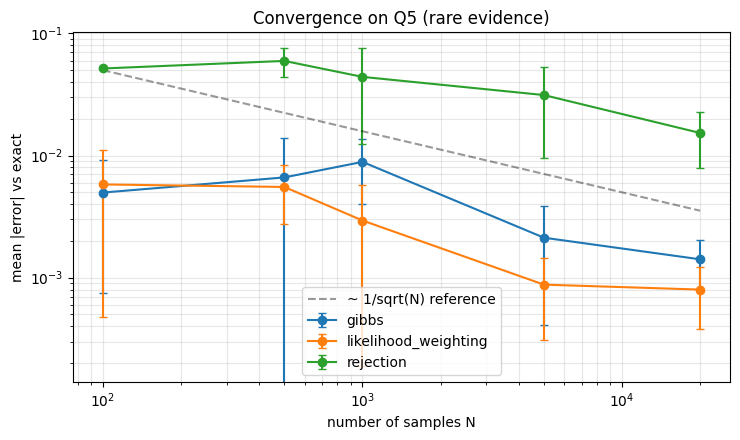

method,gibbs,likelihood_weighting,rejection
N,,,
100,0.0050,0.0058,0.0516
500,0.0066,0.0055,0.0595
1000,0.0089,0.0029,0.0441
5000,0.0021,0.0009,0.0313
20000,0.0014,0.0008,0.0153


Runs in which rejection sampling kept ZERO samples:


N,100,500,1000,5000,20000
failed_runs,2,0,0,0,0


In [12]:
conv = pd.DataFrame(approx["convergence"])
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for m, g in conv.groupby("method"):
    g = g.dropna(subset=["mean_abs_error"])
    ax.errorbar(g["N"], g["mean_abs_error"], yerr=g["std"], marker="o", capsize=3, label=m)
Ns = np.array(CONV_N); ax.plot(Ns, 0.5 / np.sqrt(Ns), "k--", alpha=.4, label="~ 1/sqrt(N) reference")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("number of samples N"); ax.set_ylabel("mean |error| vs exact")
ax.set_title(f"Convergence on {approx['convergence_query']} (rare evidence)"); ax.grid(alpha=.3, which="both"); ax.legend(); plt.tight_layout(); plt.show()
display(conv.pivot(index="N", columns="method", values="mean_abs_error").round(4))
print("Runs in which rejection sampling kept ZERO samples:")
display(conv[conv.method == "rejection"][["N", "failed_runs"]].set_index("N").T)

## 12. Stage 07 — Evaluation: how much data do we need?
**Job:** the only stage allowed to open the **answer key**. For growing cohort sizes `n` (8 random cohorts each) we learn the network with MLE and with Laplace smoothing and measure

* the average absolute error of the learned CPT entries,
* the error of the diagnosis `P(heart=yes | Q5 evidence)` computed with the learned network,
* the number of **zero probabilities** in the MLE tables.

[07_evaluation ] inputs=3 (4244 chars) -> 07_evaluation/evaluation.json (1618 chars)
(took 7.1 s)


,cpt_mae_mle,cpt_mae_bayes,inf_err_mle,inf_err_bayes,zeros_mle,inf_err_mle_failed
n,,,,,,
30,0.1681,0.1167,0.0566,0.0393,9.625,0
100,0.0858,0.0765,0.0345,0.0206,1.750,0
300,0.0514,0.0480,0.0164,0.0150,0.125,0
1000,0.0254,0.0249,0.0062,0.0060,0.000,0
3000,0.0158,0.0157,0.0065,0.0064,0.000,0
10000,0.0081,0.0081,0.0023,0.0022,0.000,0


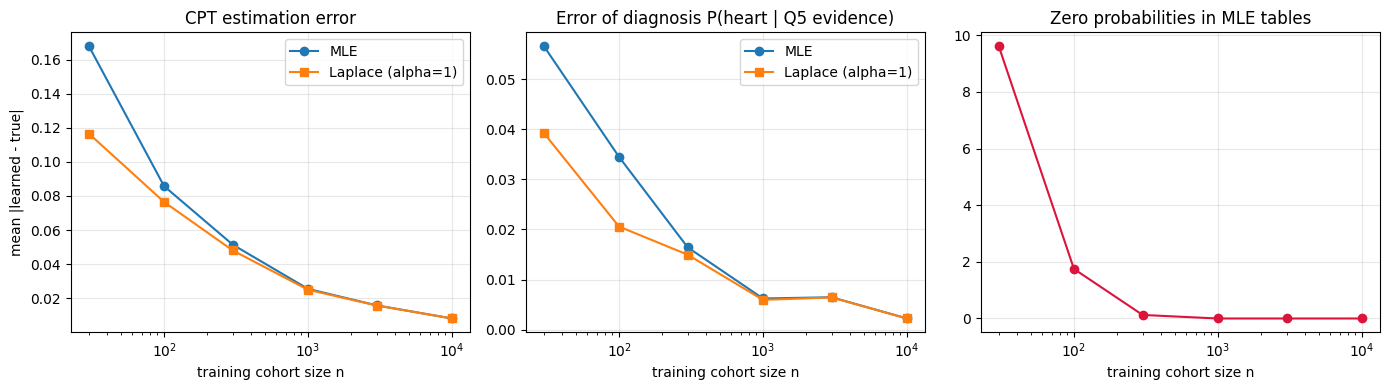

In [13]:
SIZES, EVAL_REPEATS = [30, 100, 300, 1000, 3000, 10000], 8

def sample_codes(rng, order, P, CPT, n):
    cols = {v: np.zeros(n, dtype=int) for v in order}
    for i in range(n):
        x = forward_sample(rng, P, CPT, order)
        for v in order:
            cols[v][i] = x[v]
    return cols

def stage_evaluation(loaded):
    _, S, P, _, order = load_net(loaded["01_structure/network.json"])
    TR = cpt_from_json(S, P, json.loads(loaded["99_answer_key/ground_truth_cpts.json"]))
    q = next(r for r in json.loads(loaded["04_exact/queries.json"]) if r["id"] == HARD_Q)
    e, qv, ti = ev_idx(S, q["evidence"]), q["query"], S[q["query"]].index(q["target"])
    truth_p = exact_posterior(S, P, TR, order, qv, e)[0][ti]
    def mae(CPT):
        return float(np.mean([abs(CPT[v][k] - TR[v][k]).mean() for v in TR for k in TR[v]]))
    out = []
    for n in SIZES:
        acc = {k: [] for k in ["cpt_mae_mle", "cpt_mae_bayes", "inf_err_mle", "inf_err_bayes", "zeros_mle"]}
        for r in range(EVAL_REPEATS):
            rng = np.random.default_rng(777 + 13 * n + r)
            counts = count_tables(sample_codes(rng, order, P, TR, n), S, P)
            mle, bayes = estimate(counts, S, 0.0), estimate(counts, S, 1.0)
            acc["cpt_mae_mle"].append(mae(mle)); acc["cpt_mae_bayes"].append(mae(bayes))
            acc["zeros_mle"].append(float(sum((np.array(list(rows.values())) == 0).sum() for rows in mle.values())))
            acc["inf_err_mle"].append(abs(exact_posterior(S, P, mle, order, qv, e)[0][ti] - truth_p))
            acc["inf_err_bayes"].append(abs(exact_posterior(S, P, bayes, order, qv, e)[0][ti] - truth_p))
        out.append({"n": n, **{k: float(np.nanmean(v)) for k, v in acc.items()},
                    "inf_err_mle_failed": int(np.isnan(acc["inf_err_mle"]).sum())})
    return json.dumps({"true_posterior_Q5": float(truth_p), "rows": out}, indent=2)

t0 = time.perf_counter()
_ = run_stage("07_evaluation", ["01_structure/network.json", "99_answer_key/ground_truth_cpts.json", "04_exact/queries.json"],
              stage_evaluation, "07_evaluation/evaluation.json")
print(f"(took {time.perf_counter() - t0:.1f} s)")
ev = json.loads((WS / "07_evaluation/evaluation.json").read_text())
evdf = pd.DataFrame(ev["rows"]).set_index("n")
display(evdf.round(4))

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].plot(evdf.index, evdf["cpt_mae_mle"], "o-", label="MLE"); ax[0].plot(evdf.index, evdf["cpt_mae_bayes"], "s-", label="Laplace (alpha=1)")
ax[0].set_title("CPT estimation error"); ax[0].set_ylabel("mean |learned - true|")
ax[1].plot(evdf.index, evdf["inf_err_mle"], "o-", label="MLE"); ax[1].plot(evdf.index, evdf["inf_err_bayes"], "s-", label="Laplace (alpha=1)")
ax[1].set_title("Error of diagnosis P(heart | Q5 evidence)")
ax[2].plot(evdf.index, evdf["zeros_mle"], "o-", color="crimson"); ax[2].set_title("Zero probabilities in MLE tables")
for a in ax:
    a.set_xscale("log"); a.set_xlabel("training cohort size n"); a.grid(alpha=.3)
ax[0].legend(); ax[1].legend(); plt.tight_layout(); plt.show()

## 13. Stage 08 — Report
**Job:** compile everything into a readable `report.md`.

In [14]:
def stage_report(loaded):
    ex = json.loads(loaded["04_exact/exact_results.json"]); cc = {c["id"]: c for c in json.loads(loaded["05_crosscheck/crosscheck.json"])}
    ap = json.loads(loaded["06_approx/approx_results.json"]); evl = json.loads(loaded["07_evaluation/evaluation.json"])
    lr = json.loads(loaded["03_learning/learned_cpts.json"])
    by = {(r["id"], r["method"]): r for r in ap["main"]}
    L = ["# Heart-disease risk Bayesian network - report", "", "_Educational model on a synthetic cohort - not for clinical use._", "",
         f"Learned from **{lr['n_rows']}** patients (zero probabilities in the MLE tables: **{lr['mle_zero_entries']}**; Laplace smoothing never produces any).", "",
         "## Inference results (target probability)", "",
         "| ID | Question | Exact | pgmpy ok | Rejection | Likelihood w. | Gibbs |", "|---|---|---|---|---|---|---|"]
    for r in ex:
        L.append(f"| {r['id']} | {r['question']} | {r['p_target']:.4f} | {'yes' if cc[r['id']]['pass'] else 'NO'} | "
                 + " | ".join(f"{by[(r['id'], m)]['estimate']:.4f}" for m in SAMPLERS) + " |")
    L += ["", "## Learning vs. cohort size", "", "| n | CPT error MLE | CPT error Laplace | inference error MLE | inference error Laplace | zeros in MLE |", "|---|---|---|---|---|---|"]
    for r in evl["rows"]:
        L.append(f"| {r['n']} | {r['cpt_mae_mle']:.4f} | {r['cpt_mae_bayes']:.4f} | {r['inf_err_mle']:.4f} | {r['inf_err_bayes']:.4f} | {r['zeros_mle']:.1f} |")
    L += ["", "## Take-aways", "",
          "- Learned CPTs and exact inference match pgmpy.",
          "- Rejection sampling needs far more samples when the evidence is rare (low acceptance rate).",
          "- Likelihood weighting and Gibbs sampling use every sample, but weights/correlation reduce the effective sample size.",
          "- Laplace smoothing removes zero probabilities and helps most when data are scarce."]
    return "\n".join(L)

report = run_stage("08_report", ["04_exact/exact_results.json", "05_crosscheck/crosscheck.json", "06_approx/approx_results.json",
                                 "07_evaluation/evaluation.json", "03_learning/learned_cpts.json"], stage_report, "08_report/report.md")
print(report)

[08_report     ] inputs=5 (17647 chars) -> 08_report/report.md (1790 chars)
# Heart-disease risk Bayesian network - report

_Educational model on a synthetic cohort - not for clinical use._

Learned from **5000** patients (zero probabilities in the MLE tables: **0**; Laplace smoothing never produces any).

## Inference results (target probability)

| ID | Question | Exact | pgmpy ok | Rejection | Likelihood w. | Gibbs |
|---|---|---|---|---|---|---|
| Q1 | Overall probability of heart disease | 0.1216 | yes | 0.1204 | 0.1186 | 0.1180 |
| Q2 | Older patient with low exercise (risk prediction) | 0.1571 | yes | 0.1435 | 0.1558 | 0.1564 |
| Q3 | Patient reports chest pain (diagnosis) | 0.4179 | yes | 0.4009 | 0.4180 | 0.4230 |
| Q4 | Chest pain and abnormal ECG | 0.8115 | yes | 0.7660 | 0.8166 | 0.8102 |
| Q5 | Smoker with high BP, chest pain and abnormal ECG (rare evidence) | 0.9484 | yes | 0.9394 | 0.9490 | 0.9510 |
| Q6 | Given heart disease, how likely is obesity? (backward reasoning) 

## 14. The ICM workspace

In [15]:
for p in sorted(WS.rglob("*")):
    depth = len(p.relative_to(WS).parts) - 1
    print("    " * depth + ("📁 " if p.is_dir() else "📄 ") + p.name + ("" if p.is_dir() else f"  ({p.stat().st_size} bytes)"))

📁 00_context
    📄 CONTEXT.md  (574 bytes)
📁 01_structure
    📄 network.json  (1338 bytes)
📁 02_data
    📄 patients.csv  (225212 bytes)
📁 03_learning
    📄 learned_cpts.json  (6011 bytes)
📁 04_exact
    📄 exact_results.json  (2179 bytes)
    📄 queries.json  (1183 bytes)
📁 05_crosscheck
    📄 crosscheck.json  (851 bytes)
📁 06_approx
    📄 approx_results.json  (6988 bytes)
📁 07_evaluation
    📄 evaluation.json  (1618 bytes)
📁 08_report
    📄 report.md  (1790 bytes)
📁 99_answer_key
    📄 ground_truth_cpts.json  (1723 bytes)


## 15. Conclusions
* Built a 9-node **Bayesian network for heart-disease risk** and **learned all CPTs from 5,000 patient records**; results agree with pgmpy to machine precision.
* Compared **MLE with Bayesian (Laplace) estimation**: with small cohorts MLE yields zero probabilities and noisier diagnoses, while smoothing stays stable; both converge as `n` grows.
* Implemented **rejection sampling, likelihood weighting and Gibbs sampling** from scratch and showed their trade-offs on a query with rare evidence: rejection sampling kept only ~1% of its samples on the rarest evidence and had the largest error at every sample size, while likelihood weighting and Gibbs stayed within about 0.01 of the exact answer.
* The **ICM** layout (one stage per folder, plain-text hand-offs, answer key visible only to the evaluation stage) keeps every step auditable — the interpretability principle from the TA-1 paper.

**Limitations:** synthetic data; discretised variables; a hand-designed structure (structure learning is future work); Gibbs sampling here is plain Python and not optimised.

**References:** Koller & Friedman (2009), *Probabilistic Graphical Models*; Russell & Norvig, *Artificial Intelligence: A Modern Approach* (ch. 13 — approximate inference); *Interpretable Context Methodology: Folder Structure as Agentic Architecture*, arXiv:2603.16021.